<a href="https://colab.research.google.com/github/andres-merino/AprendizajeAutomaticoInicial-05-N0105/blob/main/3-Talleres/Taller01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<table style="border: none; border-collapse: collapse;">
    <tr>
        <td style="width: 20%; vertical-align: middle; padding-right: 10px;">
            <img src="https://i.imgur.com/nt7hloA.png" width="100">
        </td>
        <td style="width: 2px; text-align: center;">
            <font color="#0030A1" size="7">|</font><br>
            <font color="#0030A1" size="7">|</font>
        </td>
        <td>
            <p style="font-variant: small-caps;"><font color="#0030A1" size="5">
                <b>Facultad de Ciencias Exactas, Naturales y Ambientales</b>
            </font> </p>
            <p style="font-variant: small-caps;"><font color="#0030A1" size="4">
                Aprendizaje Automático Inicial &bull; Taller 01
            </font></p>
            <p style="font-style: oblique;"><font color="#0030A1" size="3">
                Nombre y Apellido &bull; Fecha
            </font></p>
        </td>  
    </tr>
</table>

---
# <font color='264CC7'> Indicaciones </font>

- En esta actividad está orientada para que el estudiante *(Criterio 2.1) Emplea modelos de aprendizaje no supervisado, realizando un análisis crítico de su rendimiento y aplicabilidad en diferentes contextos*.
- Todas las soluciones deben estar correctamente redactadas, comentadas y explicadas.

---
# <font color='264CC7'> Introducción </font>

A lo largo de esta taller veremos como aplicar distintas técnicas de aprendizaje no supervisado así como algunas de sus aplicaciones reales. Para ello vamos a necesitar las siguientes librerías:

In [2]:
#Libererías base(Manejo de daos y gráficos)
import numpy as np #Librería para el cálculo numérico y manejo de arreglos/matrices.
import pandas as pd #Sirve para manejar tablas de datos(Data Frames.)
import matplotlib.pyplot as plt #Esuna herramienta para graficar. Con esto podemos crear gráficos de dispersión(plt.scatter), las curvas del método codo(plt.plot), las cuadrículas de gráficos(plt.subplots) y muestra las imágenes de los números(plt.imshow)

#Generadores y cargadores de datos
from sklearn.datasets import make_circles #Es un generador de datos sintéticos que crea puntos en 2D con forma de dos anillos concéntricos(uno dentro de otro).
from sklearn.datasets import fetch_openml #Permite descargar conjuntos de datos reales desde el repositorio OpenML.


#Algoritmos de Clustering
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster #Son tres funciones que trabajan juntas para el Agrupamiento Jerárquico. Linkage: Calcula las distancias entre los puntos y va armando las fusiones jerárquicas según el criterio que le digamos. dendrogram: Toma el resultado de linkage y dibuja el árbol jerárquico(dendograma). fcluster: Corta ese árbol a un altura o número de grupos determinado para devolver a qué clúster pertenece cada punto.
from sklearn.cluster import KMeans, DBSCAN #Importa dos de los algoritmos principales del taller desde Scikit-Learn. Kmeans: Algoritmo particional basado en centroides (distancias al centro del grupo). DBSCAN:Algoritmo basado en densidad de puntos (ideal para formas irregulares y detectar ruido/valores atípicos).

#Evaluación y reducción de dimensiones
from sklearn.metrics import silhouette_score #Calcula el índice Silueta(un valor entre -1 y 1). Sirve para evaluar matemáticamente qué tan bien quedaron los grupos (qué tan compactos están por dentro y qué tan separados están unos de otros) sin necesidad de ver las etiquetas reales.
from sklearn.decomposition import PCA #Importa el Análisis de Componentes Principales. Sirve para reducir dimensiones (por ejemplo, comprimir las 784 columnas de píxeles de MNIST a unas pocas decenas de variables que conserven al menos el 80% de la información/varianza).

---
<a id="ej1"></a>
# <font color='264CC7'> Métodos de *clustering* </font>


Este ejercicio trata de explorar distintas técnicas de agrupamiento ajustándolas a distintos conjuntos de datos.

El objetivo es doble: entender la influencia de los parámetros en su comportamiento, y conocer sus limitaciones en la búsqueda de estructuras de datos.

## <font color='264CC7'> Datos </font>

El conjunto de datos tiene 2 variables (columnas) organizadas en la matriz *X* y tantas filas como muestras. Existe también una variable que contiene las etiquetas reales de los clústeres, **pero no debe ser utilizada** durante la construcción ni la evaluación de los modelos.

El objetivo es identificar las estructuras latentes presentes en los datos mediante distintas técnicas de *clustering*.

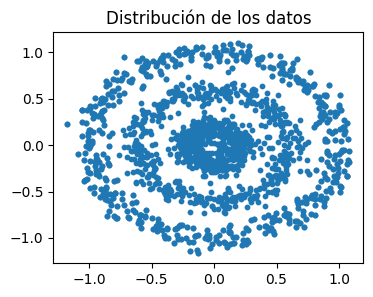

In [3]:
X_circles1, _ = make_circles(n_samples=1000, factor=.6, noise=.07, random_state=42)
X_circles2, _ = make_circles(n_samples=1000, factor=.2, noise=.07, random_state=42)

# Juntamos los datos en un solo conjunto.
X_circles = np.vstack((X_circles1, X_circles2))

# Graficamos los datos.
plt.figure(figsize=(4, 3))
plt.scatter(X_circles[:, 0], X_circles[:, 1], s=10)
plt.title('Distribución de los datos')
plt.show()

## <font color='264CC7'> k-Means Clustering </font>

### <font color='264CC7'> Parte 1: Determinación del número de clústeres </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
Aplica el método del codo para determinar el número óptimo de clústeres:
<ul>
<li>Calcula la inercia para valores de k de 1 a 10.</li>
<li>Grafica la inercia frente al número de clústeres.</li>
<li>Identifica visualmente el punto del "codo" y justifica tu elección desde una perspectiva matemática y conceptual.</li>
</ul>
</div>

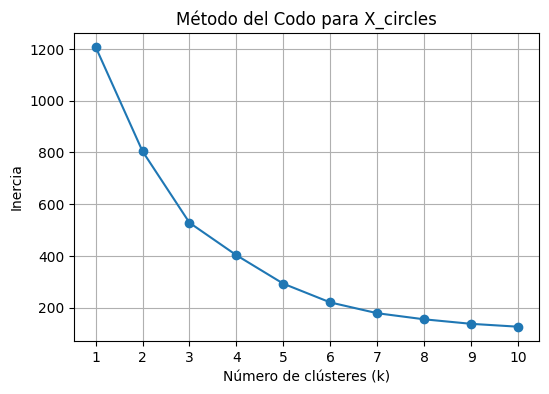

In [4]:
# 1. Preparar la lista y el rango de valores de k
inercias = []
valores_k = range(1, 11)

# 2. Ciclo para entrenar K-Means con cada valor de k
for k in valores_k:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_circles)
    inercias.append(kmeans.inertia_)

# 3. Graficar la curva del codo
plt.figure(figsize=(6, 4))
plt.plot(valores_k, inercias, marker='o', linestyle='-')
plt.xlabel('Número de clústeres (k)')
plt.ylabel('Inercia')
plt.title('Método del Codo para X_circles')
plt.xticks(valores_k)
plt.grid(True)
plt.show()

La mejor elección sería k=4, ya que es el punto donde la curva cambia bruscamente de inclinación, este punto representa el momento en el que la inercia deja de disminuir de forma acelerada y la pendiente de la curva se aplana. Esto significa que hasta ese número de clústeres el algoritmo está encontrando divisiones importantes en los datos, lo que significa que agregar más grupos a partir de ahí ya no añade información útil/nueva a los clústeres.





### <font color='264CC7'> Evaluación crítica del método </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
Entrena un modelo de K-Means con el número de clústeres seleccionado. Luego:
<ul>
<li>Grafica los datos coloreados según la asignación de clúster.</li>
<li>Explica si el modelo ha logrado identificar la estructura natural de los datos. ¿Qué limitaciones observas en el resultado?</li>
<li>Reflexiona sobre las condiciones geométricas bajo las cuales K-Means funciona adecuadamente y por qué podría no ser el algoritmo más adecuado para este tipo de distribución.</li>
</ul>
</div>

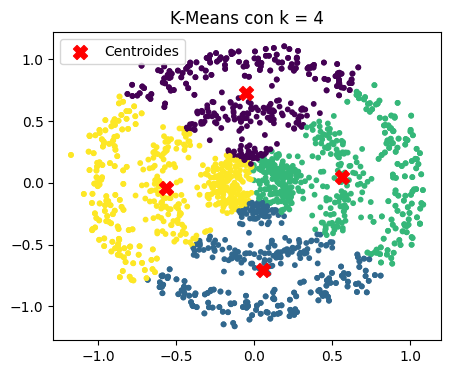

In [8]:
# 1. Definir el número óptimo de clústeres y entrenar el modelo
k_optimo = 4
kmeans_final = KMeans(n_clusters=k_optimo, random_state=42, n_init=10)

# 2. Entrenar y obtener a qué clúster pertenece cada punto
etiquetas_kmeans = kmeans_final.fit_predict(X_circles)

# 3. Graficar los datos coloreados según su clúster
plt.figure(figsize=(5, 4))
plt.scatter(X_circles[:, 0], X_circles[:, 1], c=etiquetas_kmeans, cmap='viridis', s=10)

# Graficar los centroides en rojo
centroides = kmeans_final.cluster_centers_
plt.scatter(centroides[:, 0], centroides[:, 1], c='red', marker='X', s=100, label='Centroides')

plt.title(f'K-Means con k = {k_optimo}')
plt.legend()
plt.show()

---
## <font color='264CC7'> Agrupamiento Jerárquico</font>

### <font color='264CC7'> Análisis comparativo de criterios de enlace </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
Realiza un análisis exhaustivo de agrupamiento jerárquico utilizando distintos criterios de enlace:
<ul>
  <li>Define una lista de métodos de enlace: 'single', 'complete', 'average', 'ward'.</li>
  <li>Para cada criterio, ejecuta los siguientes pasos:
    <ul>
      <li>Aplica el algoritmo de clustering jerárquico a los datos.</li>
      <li>Segmenta el dataset en tres clústeres utilizando un umbral adecuado en el dendrograma.</li>
      <li>Visualiza, para cada criterio:
        <ul>
          <li>Un gráfico de dispersión de los datos coloreados por clúster.</li>
          <li>El dendrograma correspondiente, señalando visualmente el corte realizado.</li>
        </ul>
      </li>
    </ul>
  </li>
  <li>Organiza todas las visualizaciones en un único conjunto de subplots, con dos columnas (gráfico de dispersión / dendrograma) y cuatro filas (uno por cada método de enlace).</li>
</ul>
</div>


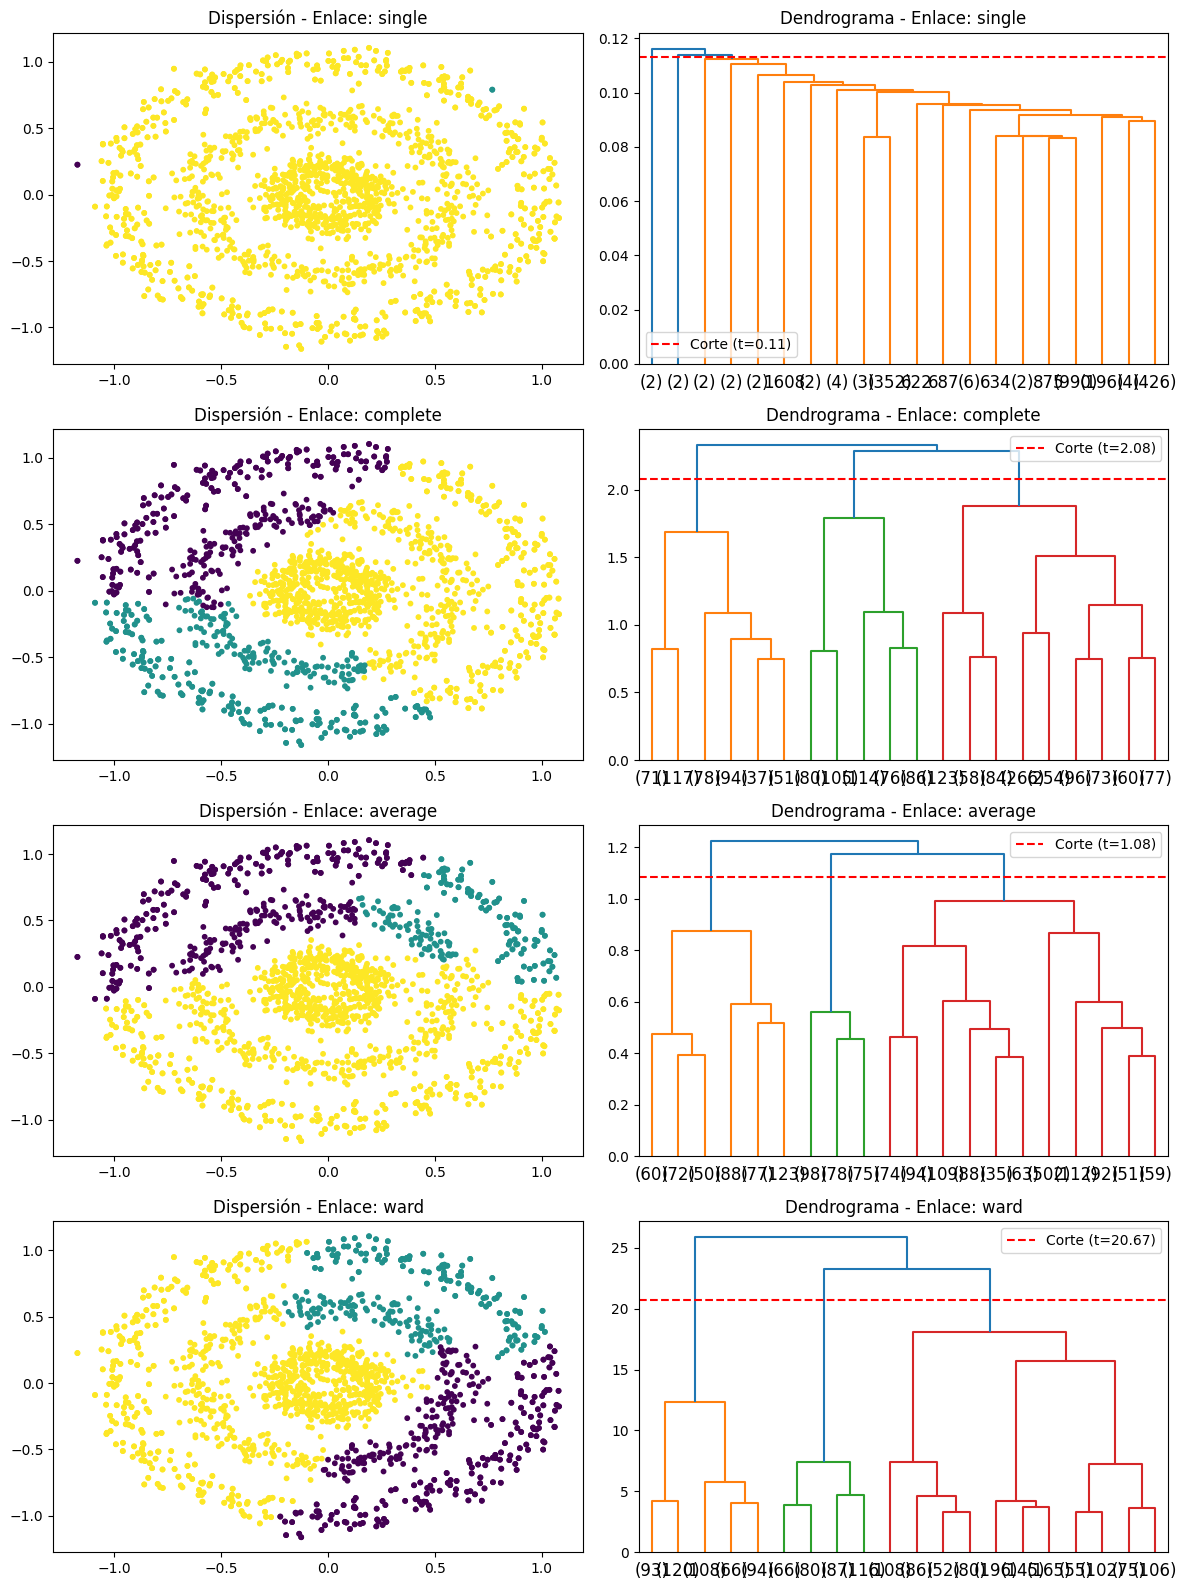

In [6]:
# 1. Definir la lista de métodos de enlace y crear la cuadrícula de gráficos (4 filas x 2 columnas)
metodos = ['single', 'complete', 'average', 'ward']
fig, axes = plt.subplots(4, 2, figsize=(12, 16))

# 2. Iterar sobre cada método
for i, metodo in enumerate(metodos):
    # a) Calcular la matriz de enlaces jerárquicos (Z)
    Z = linkage(X_circles, method=metodo)

    # b) Calcular el umbral de altura exacto en el dendrograma para obtener 3 clústeres
    # Z[:, 2] guarda las distancias de fusión. Cortamos justo entre la penúltima y antepenúltima fusión
    umbral = (Z[-3, 2] + Z[-2, 2]) / 2

    # c) Segmentar los datos en 3 clústeres usando ese umbral de distancia
    etiquetas = fcluster(Z, t=umbral, criterion='distance')

    # d) Columna izquierda (0): Gráfico de dispersión coloreado por clúster
    axes[i, 0].scatter(X_circles[:, 0], X_circles[:, 1], c=etiquetas, cmap='viridis', s=10)
    axes[i, 0].set_title(f'Dispersión - Enlace: {metodo}')

    # e) Columna derecha (1): Dendrograma y línea horizontal del corte
    dendrogram(Z, truncate_mode='lastp', p=20, ax=axes[i, 1], color_threshold=umbral)
    axes[i, 1].axhline(y=umbral, color='red', linestyle='--', label=f'Corte (t={umbral:.2f})')
    axes[i, 1].set_title(f'Dendrograma - Enlace: {metodo}')
    axes[i, 1].legend()

plt.tight_layout()
plt.show()


### <font color='264CC7'> Evaluación crítica del método </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
Analiza y responde:
<ul>
  <li>¿Cuál de los métodos ('single', 'complete', 'average', 'ward') ha capturado mejor la estructura subyacente de los datos? Justifica tu respuesta en términos de:
    <ul>
      <li>Separabilidad visual de los clústeres.</li>
      <li>Forma y cohesión de los grupos encontrados.</li>
      <li>Propiedades geométricas del dataset inicial.</li>
    </ul>
  </li>
  <li>Discute brevemente una ventaja y una desventaja del uso de agrupamiento jerárquico frente a métodos particionales como K-Means en este tipo de problemas.</li>
</ul>
</div>

El método single es el único que logra identificar bien la estructura real de los datos, separando visualmente los tres anillos completos, mientras que los otros métodos fallan porque parten los círculos en pedazos. Esto pasa por la forma circular de los datos: mientras que los otros tres métodos buscan crear grupos redondos y compactos alrededor de un centro, el método single solo se fija en unir cada punto con su vecino más cercano. Finalmente, una gran ventaja del agrupamiento jerárquico frente a K-Means es que no necesitas adivinar desde el principio cuántos grupos quieres (puedes ver el árbol completo primero y decidir dónde cortar después) y además sí logra reconocer formas curvas; en cambio, su principal desventaja es que es mucho más lento y pesado para la computadora porque tiene que calcular las distancias de todos los puntos contra todos.   

---
## <font color='264CC7'> Algoritmos basados en densidad: DBSCAN </font>

### <font color='264CC7'> Ajuste de parámetros y análisis </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
Explora el comportamiento de DBSCAN variando el parámetro <code>eps</code>:
<ul>
  <li>Aplica el algoritmo DBSCAN con <code>min_samples=5</code> y <code>eps</code> en los valores {0.07, 0.08, 0.09, 0.10}.</li>
  <li>Para cada configuración:
    <ul>
      <li>Visualiza los resultados mediante un gráfico de dispersión, coloreando por clúster e identificando valores atípicos (noise).</li>
      <li>Incluye el número de clústeres y el porcentaje de puntos clasificados como ruido en el título de cada gráfico.</li>
    </ul>
  </li>
  <li>Organiza las visualizaciones en subplots (2 filas x 2 columnas).</li>
  <li>Selecciona el mejor valor de <code>eps</code> con base en:
    <ul>
      <li>Separación visual de los clústeres.</li>
      <li>Minimización de puntos etiquetados como ruido, sin pérdida de estructura natural.</li>
    </ul>
  </li>
  <li>Justifica tu elección en no más de cinco líneas.</li>
</ul>
</div>

### <font color='264CC7'> Profundización en el ajuste de <code>min_samples</code> </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
Con el mejor valor de <code>eps</code> encontrado:
<ul>
  <li>Varia el parámetro <code>min_samples</code> en los valores {4, 5, 6, 7}.</li>
  <li>Para cada caso:
    <ul>
      <li>Visualiza los resultados mediante un gráfico de dispersión, con la misma codificación de colores.</li>
      <li>Indica en el título el número de clústeres detectados y el porcentaje de ruido.</li>
    </ul>
  </li>
  <li>Organiza los resultados en subplots (2 filas x 2 columnas).</li>
  <li>Compara los efectos de variar <code>min_samples</code> sobre la detección de clústeres y la sensibilidad ante el ruido.</li>
</ul>
</div>

### <font color='264CC7'> Análisis </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
Reflexiona críticamente sobre los resultados obtenidos:
<ul>
  <li>Describe cómo cambiaron los clústeres y la cantidad de ruido al variar los parámetros <code>eps</code> y <code>min_samples</code>.</li>
  <li>Explica qué configuraciones favorecieron una mejor separación de los clústeres naturales.</li>
  <li>Justifica, con base en las características geométricas del dataset (círculos), por qué DBSCAN puede detectar estructuras que otros métodos como K-Means no identifican adecuadamente.</li>
</ul>
</div>


---
<a id="ej2"></a>
# <font color='264CC7'> Ejemplo práctico</font>

Trabajarás con un subconjunto del conjunto de datos **MNIST**, que contiene imágenes de dígitos escritos a mano. Tu objetivo es aplicar técnicas de *clustering* para agrupar las imágenes según patrones estructurales, sin usar las etiquetas reales.

Utilizarás los siguientes datos (cambia la semilla por los últimos 2 dígitos de tu cédula):

In [ ]:
# Cargamos el dataset MNIST
X, y = fetch_openml('mnist_784', return_X_y=True, parser='auto')

# Tomo aleatoriamente 1000 muestras
np.random.seed(75) # Cambiar por último dos dígitos de la cédula
indices = np.random.choice(len(X), 5000, replace=False)
X = X.iloc[indices]
y = y[indices]
# Reinicio los índices
X.reset_index(drop=True, inplace=True)

display(X.head())

,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,pixel10,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


### <font color='264CC7'> Introducción y Contexto </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
Investiga:
<ul>
  <li>¿Qué es el dataset MNIST y cuál es su relevancia en la investigación en Machine Learning?</li>
  <li>Describe su estructura: ¿qué representan las filas y las columnas?</li>
  <li>Incluye al menos dos referencias bibliográficas correctamente citadas.</li>
</ul>
</div>


Para poder visualizar los datos, los convertiremos en un formato de imagen.

In [ ]:
# Reorganizar los datos para que sean imágenes
n_images = X.shape[0]
X_images = X.to_numpy().reshape(n_images, 28, 28)
X = X_images.reshape(n_images, 28 * 28)

Con esto, podemos visualizar las imágenes de los dígitos y analizar los resultados obtenidos. Por ejemplo:

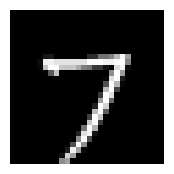

In [ ]:
# Graficamos una imagen
plt.figure(figsize=(2, 2))
plt.imshow(X_images[75], cmap='gray') # Cambiar por últimos dígitos de tu cédula
plt.axis('off')
plt.show()

---

## <font color='264CC7'> k-Means </font>

### <font color='264CC7'> Determinación del número de clústeres </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
Aplica el método del codo para determinar el número óptimo de clústeres:
<ul>
  <li>Entrena modelos de K-Means para valores de k entre 1 y 20.</li>
  <li>Genera una gráfica de inercia frente al número de clústeres.</li>
  <li>Identifica visualmente el punto del "codo" y selecciona el número óptimo de clústeres.</li>
  <li>Discute:
    <ul>
      <li>¿El número óptimo coincide con el número de dígitos (0–9)?</li>
      <li>¿Qué dificultades podría presentar este conjunto de datos para el método de K-Means?</li>
    </ul>
  </li>
</ul>
</div>

### <font color='264CC7'> Asignación de grupos y visualización </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
Asigna los datos a los clústeres obtenidos:
<ul>
  <li>Muestra cinco imágenes aleatorias de cada clúster asignado.</li>
  <li>Organiza las imágenes en una figura clara y etiquetada.</li>
</ul>
</div>

### <font color='264CC7'> Descripción de los clústeres </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
Analiza los grupos formados:
<ul>
  <li>Describe las principales características visuales de cada grupo.</li>
  <li>Asigna un "nombre" representativo a cada clúster (por ejemplo: "número 3 estilizado", "número 8 redondeado", etc.).</li>
</ul>
</div>

### <font color='264CC7'> Evaluación cuantitativa de los clústeres </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
Evalúa objetivamente la calidad de los clústeres:
<ul>
  <li>Calcula el promedio del índice de silueta para la partición obtenida.</li>
  <li>Interpreta el valor: ¿qué tan compactos y bien separados son los grupos?</li>
</ul>
</div>

---
## <font color='264CC7'> Reducción de dimensiones y k-Means </font>

### <font color='264CC7'> Reducción de dimensiones </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Realiza una reducción de dimensiones de los datos utilizando PCA.
<ul>
  <li>Realiza un análisis de componentes principales para 100 componentes y grafica la varianza explicada acumulada.</li>
  <li>Selecciona el número de componentes principales que expliquen al menos el 80% de la varianza.</li>
  <li>Transforma los datos originales en el espacio de las componentes principales.</li>
</ul>
</div>

### <font color='264CC7'> Determinación del número de clusters </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Determina el número óptimo de clústeres para un modelo K-Means utilizando el método del codo.
<ul>
  <li>Genera una gráfica que muestre la inercia frente al número de clústeres (k) en el rango de 1 a 20.</li>
  <li>Identifica visualmente el «codo» en la curva para seleccionar el número óptimo de clústeres.</li>
  <li>¿Concuerda tu elección con el número de dígitos que se esperan en el conjunto de datos? Explica qué está pasando.</li>
</ul>
</div>

### <font color='264CC7'> Asignación de grupos y análisis </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Realiza un análisis de los grupos obtenidos.
<ul>
  <li>Asigna los grupos.</li>
  <li>Muestra 5 integrantes de cada grupo (como imágenes).</li>
</ul>
</div>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Da una descripción de los grupos obtenidos. Asigna un nombre a cada grupo.
</div>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
Calcula la métrica de la silueta para los grupos obtenidos. ¿Qué tan buenos te parecen los grupos?
</div>

---
## <font color='264CC7'> Análisis finial</font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Realiza un análisis crítico de los resultados obtenidos en los distintos modelos de *clustering*. ¿Qué modelo se ha comportado mejor? ¿Por qué?
</div>
